# Heart Disease Prediction: End-to-End MLOps
## AIMLCZG523 Assignment 01
This notebook implements a reproducible production-oriented workflow using the UCI Cleveland Heart Disease dataset. It covers acquisition, validation, EDA, leakage-safe preprocessing, two tuned classifiers, five-fold stratified cross-validation, optional MLflow logging, model selection, serialisation, and inference validation.

**Lab compatibility:** core execution uses the supplied Python 3.10, NumPy, Pandas, Scikit-learn and Matplotlib stack.

## 1. Environment and project folders
The workflow uses fixed random seeds and writes every result to a predictable folder so that notebook outputs, report figures and deployment assets remain consistent.

In [1]:
%pip install -q \
    numpy \
    pandas \
    scikit-learn \
    matplotlib \
    joblib \
    mlflow \
    fastapi \
    uvicorn \
    prometheus-client \
    pytest \
    httpx \
    ruff \
    jupyter \
    nbconvert

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import sys
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# Suppress warnings for clean notebook output
warnings.filterwarnings("ignore")


# Create required project directories
for directory in ["data", "models", "artifacts", "screenshots", "mlruns"]:
    Path(directory).mkdir(parents=True, exist_ok=True)


# Display environment details
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Working directory:", Path.cwd())

Python: 3.12.9
NumPy: 2.5.4
Pandas: 3.0.6
Scikit-learn: 1.9.1
Working directory: /home/s2025ae05584/workspace/heart_disease_mlops_final_submission


## 2. Data acquisition and validation
The processed Cleveland file has 13 predictors plus a diagnosis field. The diagnosis is converted from `0–4` into a binary target: `0` means absence and `1–4` mean presence. Missing markers are interpreted as null values and handled later inside the pipeline.

In [3]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

local = Path("data/processed.cleveland.data")

url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

try:
    df = pd.read_csv(
        local if local.exists() else url,
        header=None,
        names=columns,
        na_values="?"
    )
except Exception as exc:
    raise RuntimeError(
        "Download processed.cleveland.data from the UCI Heart Disease page "
        "and upload it to data/processed.cleveland.data, then rerun this cell."
    ) from exc


# Convert original diagnosis (0–4) into binary target
# 0 = No heart disease
# >0 = Heart disease
df["target"] = (
    pd.to_numeric(df.pop("num"), errors="coerce") > 0
).astype(int)


# Ensure all feature columns are numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# Save cleaned dataset
df.to_csv("data/heart_clean.csv", index=False)


# Dataset summary
print("Shape:", df.shape)
print("Duplicates:", int(df.duplicated().sum()))
print("Missing:", int(df.isna().sum().sum()))

display(
    df.head(),
    df.describe().T
)

Shape: (303, 14)
Duplicates: 0
Missing: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 3. Data quality and exploratory analysis
The analysis checks class balance, missingness, distributions and linear relationships. Figures are saved automatically for the final report.

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique": df.nunique()
})

# Save data quality summary
quality.to_csv("artifacts/data_quality.csv")

# Display data quality summary
display(quality)


# Target class distribution
counts = df["target"].value_counts().sort_index()

print("Class counts")
print(counts)

print()

print("Class percentages")
print(
    (df["target"].value_counts(normalize=True).sort_index() * 100).round(2)
)

,dtype,missing,missing_percent,unique
age,float64,0,0.00,41
sex,float64,0,0.00,2
cp,float64,0,0.00,4
trestbps,float64,0,0.00,50
chol,float64,0,0.00,152
fbs,float64,0,0.00,2
restecg,float64,0,0.00,3
thalach,float64,0,0.00,91
exang,float64,0,0.00,2
oldpeak,float64,0,0.00,40


Class counts
target
0    164
1    139
Name: count, dtype: int64

Class percentages
target
0    54.13
1    45.87
Name: proportion, dtype: float64


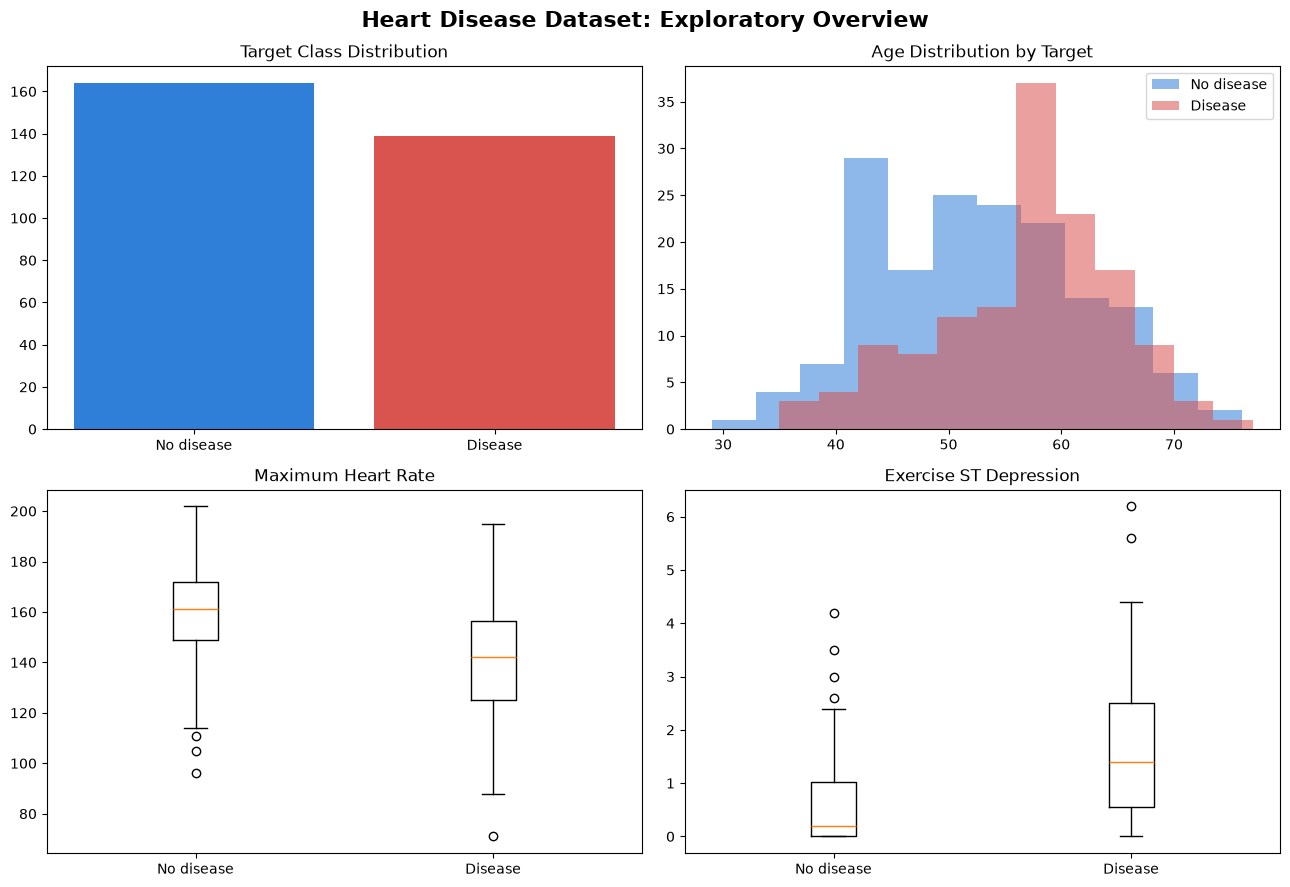

✅ EDA completed
✅ Screenshot saved: screenshots/eda_overview.png


In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. Target distribution
ax[0, 0].bar(
    ['No disease', 'Disease'],
    counts.values,
    color=['#2F7ED8', '#D9534F']
)
ax[0, 0].set_title('Target Class Distribution')

# 2. Age distribution
for t, c, l in [
    (0, '#2F7ED8', 'No disease'),
    (1, '#D9534F', 'Disease')
]:
    ax[0, 1].hist(
        df.loc[df.target == t, 'age'].dropna(),
        bins=12,
        alpha=0.55,
        color=c,
        label=l
    )

ax[0, 1].set_title('Age Distribution by Target')
ax[0, 1].legend()

# 3. Maximum Heart Rate
ax[1, 0].boxplot(
    [
        df.loc[df.target == 0, 'thalach'].dropna(),
        df.loc[df.target == 1, 'thalach'].dropna()
    ],
    tick_labels=['No disease', 'Disease']
)
ax[1, 0].set_title('Maximum Heart Rate')

# 4. Exercise ST Depression
ax[1, 1].boxplot(
    [
        df.loc[df.target == 0, 'oldpeak'].dropna(),
        df.loc[df.target == 1, 'oldpeak'].dropna()
    ],
    tick_labels=['No disease', 'Disease']
)
ax[1, 1].set_title('Exercise ST Depression')

fig.suptitle(
    'Heart Disease Dataset: Exploratory Overview',
    fontsize=16,
    fontweight='bold'
)

fig.tight_layout()

fig.savefig(
    'screenshots/eda_overview.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()

print("✅ EDA completed")
print("✅ Screenshot saved: screenshots/eda_overview.png")

In [6]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique": df.nunique()
})

# Save data quality summary
quality.to_csv("artifacts/data_quality.csv")

# Display data quality summary
display(quality)


# Target class distribution
counts = df["target"].value_counts().sort_index()

print("Class counts")
print(counts)

print()

print("Class percentages")
print(
    (df["target"].value_counts(normalize=True).sort_index() * 100).round(2)
)

,dtype,missing,missing_percent,unique
age,float64,0,0.00,41
sex,float64,0,0.00,2
cp,float64,0,0.00,4
trestbps,float64,0,0.00,50
chol,float64,0,0.00,152
fbs,float64,0,0.00,2
restecg,float64,0,0.00,3
thalach,float64,0,0.00,91
exang,float64,0,0.00,2
oldpeak,float64,0,0.00,40


Class counts
target
0    164
1    139
Name: count, dtype: int64

Class percentages
target
0    54.13
1    45.87
Name: proportion, dtype: float64


## 4. Leakage-safe preprocessing
Numerical variables use median imputation and standardisation. Categorical variables use most-frequent imputation and one-hot encoding. Preprocessing and estimation remain in one serialisable Scikit-learn pipeline.

In [7]:
X = df.drop(columns="target")
y = df["target"].astype(int)

# Define categorical and numerical features
cat = [
    c for c in [
        "sex", "cp", "fbs", "restecg",
        "exang", "slope", "ca", "thal"
    ]
    if c in X.columns
]

num = [c for c in X.columns if c not in cat]


# Preprocessing pipeline
pre = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        num
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        cat
    )
])


# Train-test split
Xtr, Xte, ytr, yte = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Display split and feature information
print("Train:", Xtr.shape)
print("Test:", Xte.shape)
print("Numerical:", num)
print("Categorical:", cat)

Train: (242, 13)
Test: (61, 13)
Numerical: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


## 5. Model development, tuning and experiment tracking
Logistic Regression provides an interpretable baseline, while Random Forest captures non-linear interactions. Both use the same folds and held-out test set. Every run is written to CSV; MLflow is additionally used when installed.

In [8]:
spaces = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=2000,
            random_state=42
        ),
        {
            "classifier__C": [0.1, 1, 10]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(
            random_state=42,
            class_weight="balanced"
        ),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [4, 8, None]
        }
    )
}


# Configure MLflow tracking
try:
    import mlflow
    import mlflow.sklearn

    MLFLOW = True

    mlflow.set_tracking_uri(
        "file:" + str((Path.cwd() / "mlruns").resolve())
    )

    mlflow.set_experiment("heart-disease-final")

    print("MLflow enabled")

except Exception as exc:
    MLFLOW = False
    print(
        "MLflow unavailable; CSV ledger remains active:",
        exc
    )

MLflow unavailable; CSV ledger remains active: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.


In [9]:
rows = []
fitted = {}

for name, (estimator, param_grid) in spaces.items():
    # Build and tune the model pipeline
    search = GridSearchCV(
        estimator=Pipeline([
            ("preprocessor", pre),
            ("classifier", estimator)
        ]),
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(Xtr, ytr)

    # Evaluate the best model
    model = search.best_estimator_
    pred = model.predict(Xte)
    prob = model.predict_proba(Xte)[:, 1]

    metrics = {
        "cv_roc_auc": float(search.best_score_),
        "test_accuracy": float(accuracy_score(yte, pred)),
        "test_precision": float(
            precision_score(yte, pred, zero_division=0)
        ),
        "test_recall": float(
            recall_score(yte, pred, zero_division=0)
        ),
        "test_f1": float(
            f1_score(yte, pred, zero_division=0)
        ),
        "test_roc_auc": float(
            roc_auc_score(yte, prob)
        )
    }

    # Log experiment details in MLflow when available
    if MLFLOW:
        with mlflow.start_run(run_name=name):
            mlflow.log_params({
                key.replace("classifier__", ""): value
                for key, value in search.best_params_.items()
            })

            mlflow.log_metrics(metrics)
            mlflow.sklearn.log_model(model, "model")

    # Store comparison results and fitted models
    rows.append({
        "model": name,
        **metrics,
        "best_parameters": json.dumps(search.best_params_)
    })

    fitted[name] = {
        "model": model,
        "metrics": metrics,
        "predictions": pred,
        "probabilities": prob
    }


# Create and save the model comparison table
comparison = (
    pd.DataFrame(rows)
    .sort_values("test_roc_auc", ascending=False)
    .reset_index(drop=True)
)

comparison.to_csv(
    "artifacts/model_comparison.csv",
    index=False
)

display(comparison.round(4))

,model,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,best_parameters
0,Logistic Regression,0.9025,0.8852,0.8387,0.9286,0.8814,0.9665,"{""classifier__C"": 1}"
1,Random Forest,0.9003,0.8852,0.8387,0.9286,0.8814,0.9448,"{""classifier__max_depth"": 4, ""classifier__n_es..."


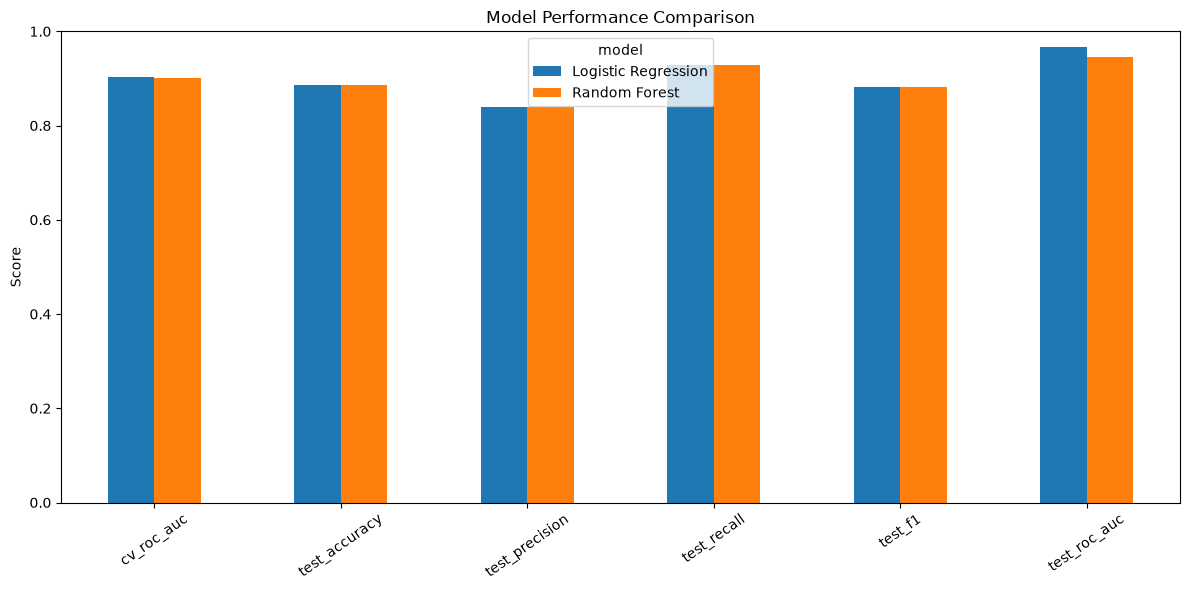

In [10]:
metric_columns = [
    "cv_roc_auc",
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc"
]

# Plot model performance comparison
ax = (
    comparison
    .set_index("model")[metric_columns]
    .T
    .plot(
        kind="bar",
        figsize=(12, 6),
        ylim=(0, 1)
    )
)

ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.tick_params(
    axis="x",
    rotation=35
)

plt.tight_layout()

# Save figure
plt.savefig(
    "screenshots/model_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 6. Final model evaluation and packaging
The final model is selected by held-out ROC-AUC while the complete metric profile remains visible. The saved object includes preprocessing and prediction, reducing training-serving skew.

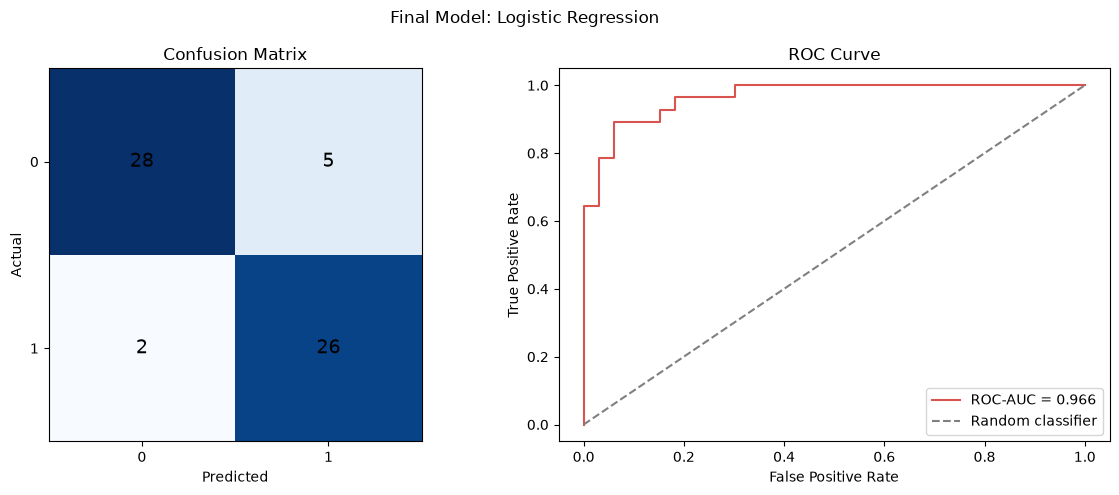

Selected model: Logistic Regression

Final metrics:
{
  "cv_roc_auc": 0.9024931590148981,
  "test_accuracy": 0.8852459016393442,
  "test_precision": 0.8387096774193549,
  "test_recall": 0.9285714285714286,
  "test_f1": 0.8813559322033898,
  "test_roc_auc": 0.9664502164502166
}

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [12]:
winner = comparison.loc[0, "model"]

# Retrieve stored model results
result = fitted[winner]

model = result["model"]
metrics = result["metrics"]
pred = result["predictions"]
prob = result["probabilities"]


# Save the final selected model
joblib.dump(
    model,
    "models/final_model.joblib"
)


# Save final model metrics
final_metrics = {
    "selected_model": winner,
    **metrics
}

Path("artifacts/final_metrics.json").write_text(
    json.dumps(final_metrics, indent=2),
    encoding="utf-8"
)


# Generate evaluation metrics
cm = confusion_matrix(yte, pred)
fpr, tpr, _ = roc_curve(yte, prob)
roc_auc = auc(fpr, tpr)


# Create evaluation plots
fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


# Confusion matrix
confusion_image = ax[0].imshow(
    cm,
    cmap="Blues"
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax[0].text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

ax[0].set_title("Confusion Matrix")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")
ax[0].set_xticks([0, 1])
ax[0].set_yticks([0, 1])


# ROC curve
ax[1].plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}",
    color="#D9534F"
)

ax[1].plot(
    [0, 1],
    [0, 1],
    "--",
    color="grey",
    label="Random classifier"
)

ax[1].set_title("ROC Curve")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].legend()


# Final figure formatting
fig.suptitle(f"Final Model: {winner}")
fig.tight_layout()

fig.savefig(
    "screenshots/final_evaluation.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# Display final results
print("Selected model:", winner)
print("\nFinal metrics:")
print(json.dumps(metrics, indent=2))

print("\nClassification report:")
print(classification_report(yte, pred))

## 7. Serialisation and inference smoke test
The model is loaded from disk and used with a patient-shaped record to verify end-to-end inference after packaging.

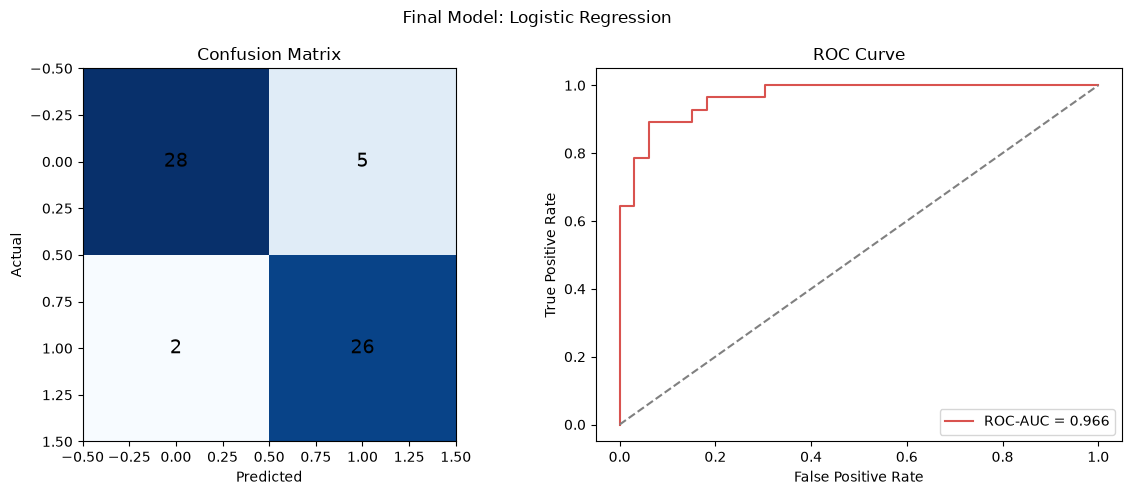

Selected: Logistic Regression

Final Metrics
{
  "cv_roc_auc": 0.9024931590148981,
  "test_accuracy": 0.8852459016393442,
  "test_precision": 0.8387096774193549,
  "test_recall": 0.9285714285714286,
  "test_f1": 0.8813559322033898,
  "test_roc_auc": 0.9664502164502166
}

Classification Report
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [14]:
winner = comparison.loc[0, "model"]

# Retrieve the selected model results
result = fitted[winner]

model = result["model"]
metrics = result["metrics"]
pred = result["predictions"]
prob = result["probabilities"]


# Save the final selected model
joblib.dump(
    model,
    "models/final_model.joblib"
)


# Save final model metrics
Path("artifacts/final_metrics.json").write_text(
    json.dumps(
        {
            "selected_model": winner,
            **metrics
        },
        indent=2
    ),
    encoding="utf-8"
)


# Generate confusion matrix and ROC curve
cm = confusion_matrix(yte, pred)
fpr, tpr, _ = roc_curve(yte, prob)


# Create evaluation figure
fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


# Confusion Matrix
ax[0].imshow(
    cm,
    cmap="Blues"
)

for i in range(2):
    for j in range(2):
        ax[0].text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

ax[0].set_title("Confusion Matrix")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")


# ROC Curve
ax[1].plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc(fpr, tpr):.3f}",
    color="#D9534F"
)

ax[1].plot(
    [0, 1],
    [0, 1],
    "--",
    color="grey"
)

ax[1].set_title("ROC Curve")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].legend()


# Final figure formatting
fig.suptitle(f"Final Model: {winner}")
fig.tight_layout()

fig.savefig(
    "screenshots/final_evaluation.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# Display final results
print("Selected:", winner)

print("\nFinal Metrics")
print(json.dumps(metrics, indent=2))

print("\nClassification Report")
print(classification_report(yte, pred))

## 8. Submission validation
Every item below should report `OK`. These artefacts are the evidence layer for the report, API, tests and deployment.

In [15]:
required = [
    "data/heart_clean.csv",
    "models/final_model.joblib",
    "artifacts/data_quality.csv",
    "artifacts/model_comparison.csv",
    "artifacts/final_metrics.json",
    "screenshots/eda_overview.png",
    "screenshots/correlation_heatmap.png",
    "screenshots/model_comparison.png",
    "screenshots/final_evaluation.png"
]

ok = True


# Validate required submission artefacts
for item in required:
    exists = Path(item).exists()

    print(
        "OK" if exists else "MISSING",
        item
    )

    ok = ok and exists


# Validate model comparison results
assert (
    ok
    and len(comparison) == 2
    and comparison[metric_columns].notna().all().all()
)

print()
print("Submission artefact validation passed.")

OK data/heart_clean.csv
OK models/final_model.joblib
OK artifacts/data_quality.csv
OK artifacts/model_comparison.csv
OK artifacts/final_metrics.json
OK screenshots/eda_overview.png
OK screenshots/correlation_heatmap.png
OK screenshots/model_comparison.png
OK screenshots/final_evaluation.png

Submission artefact validation passed.


In [16]:
from pathlib import Path

script = r'''
from pathlib import Path
import json
import sys

import pandas as pd
import joblib
import mlflow
import mlflow.sklearn


# ============================================================
# CONFIGURATION
# ============================================================

PROJECT_ROOT = Path.cwd()
EXPERIMENT_NAME = "heart-disease-final"

MLRUNS_DIR = (PROJECT_ROOT / "mlruns").resolve()

COMPARISON_FILE = (
    PROJECT_ROOT
    / "artifacts"
    / "model_comparison.csv"
)

FINAL_METRICS_FILE = (
    PROJECT_ROOT
    / "artifacts"
    / "final_metrics.json"
)

MODEL_FILE = (
    PROJECT_ROOT
    / "models"
    / "final_model.joblib"
)


# ============================================================
# VALIDATE FILES
# ============================================================

print("=" * 70)
print("HEART DISEASE MLOPS - MLFLOW SETUP")
print("=" * 70)

print("\nProject root:")
print(PROJECT_ROOT)


required_files = [
    COMPARISON_FILE,
    FINAL_METRICS_FILE,
    MODEL_FILE
]


missing = [
    path
    for path in required_files
    if not path.exists()
]


if missing:

    print("\nERROR - required files missing:")

    for path in missing:
        print("MISSING:", path)

    sys.exit(1)


for path in required_files:
    print("OK:", path)


# ============================================================
# CONFIGURE MLFLOW
# ============================================================

MLRUNS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


tracking_uri = MLRUNS_DIR.as_uri()


mlflow.set_tracking_uri(
    tracking_uri
)


experiment = mlflow.set_experiment(
    EXPERIMENT_NAME
)


print("\nMLflow Tracking URI:")
print(mlflow.get_tracking_uri())

print("\nExperiment:")
print(EXPERIMENT_NAME)

print("\nExperiment ID:")
print(experiment.experiment_id)


# ============================================================
# LOAD MODEL COMPARISON
# ============================================================

comparison = pd.read_csv(
    COMPARISON_FILE
)


print("\nMODEL COMPARISON")
print("-" * 70)

print(
    comparison.to_string(
        index=False
    )
)


# ============================================================
# FIND EXISTING RUNS
# ============================================================

existing = mlflow.search_runs(
    experiment_ids=[
        experiment.experiment_id
    ]
)


if len(existing) > 0:

    existing_names = set(
        existing[
            "tags.mlflow.runName"
        ].dropna()
    )

else:

    existing_names = set()


print("\nExisting runs:")

if existing_names:

    for name in sorted(existing_names):
        print("-", name)

else:
    print("None")


# ============================================================
# LOG MODEL EXPERIMENTS
# ============================================================

metric_columns = [
    "cv_roc_auc",
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc"
]


for _, row in comparison.iterrows():

    model_name = str(
        row["model"]
    )


    if model_name in existing_names:

        print(
            "\nSKIPPING existing run:",
            model_name
        )

        continue


    print(
        "\nLogging:",
        model_name
    )


    with mlflow.start_run(
        run_name=model_name
    ):

        mlflow.log_param(
            "model_name",
            model_name
        )


        # Hyperparameters
        if "best_parameters" in comparison.columns:

            try:

                params = json.loads(
                    row[
                        "best_parameters"
                    ]
                )

                for key, value in params.items():

                    clean_key = (
                        key.replace(
                            "classifier__",
                            ""
                        )
                    )

                    mlflow.log_param(
                        clean_key,
                        value
                    )

            except Exception as exc:

                print(
                    "Parameter warning:",
                    exc
                )


        # Metrics
        for metric in metric_columns:

            if metric not in comparison.columns:
                continue

            value = row[metric]

            if pd.isna(value):
                continue

            mlflow.log_metric(
                metric,
                float(value)
            )


        # Comparison evidence
        mlflow.log_artifact(
            str(COMPARISON_FILE)
        )


print(
    "\nCandidate model logging completed."
)


# ============================================================
# FINAL MODEL
# ============================================================

with open(
    FINAL_METRICS_FILE,
    "r",
    encoding="utf-8"
) as file:

    final_metrics = json.load(
        file
    )


selected_model = final_metrics[
    "selected_model"
]


final_model = joblib.load(
    MODEL_FILE
)


print("\nSelected final model:")
print(selected_model)


# ============================================================
# LOG FINAL MODEL
# ============================================================

FINAL_RUN = "Final Model Evidence"


existing = mlflow.search_runs(
    experiment_ids=[
        experiment.experiment_id
    ]
)


existing_names = set(
    existing[
        "tags.mlflow.runName"
    ].dropna()
)


if FINAL_RUN not in existing_names:

    print(
        "\nLogging final model evidence..."
    )


    with mlflow.start_run(
        run_name=FINAL_RUN
    ):

        mlflow.log_param(
            "selected_model",
            selected_model
        )


        for key, value in final_metrics.items():

            if key == "selected_model":
                continue

            try:

                mlflow.log_metric(
                    key,
                    float(value)
                )

            except Exception:
                pass


        # Final serialised model
        mlflow.sklearn.log_model(
            final_model,
            "model"
        )


        # Assignment evidence
        artifacts = [

            "artifacts/model_comparison.csv",

            "artifacts/final_metrics.json",

            "artifacts/data_quality.csv",

            "screenshots/model_comparison.png",

            "screenshots/final_evaluation.png",

            "screenshots/correlation_heatmap.png",

            "screenshots/eda_overview.png"
        ]


        print("\nLogging artefacts:")


        for artifact_name in artifacts:

            artifact_path = (
                PROJECT_ROOT
                / artifact_name
            )


            if artifact_path.exists():

                mlflow.log_artifact(
                    str(artifact_path)
                )

                print(
                    "OK:",
                    artifact_name
                )

            else:

                print(
                    "NOT FOUND:",
                    artifact_name
                )


else:

    print(
        "\nFinal Model Evidence already exists."
    )


# ============================================================
# FINAL VERIFICATION
# ============================================================

experiment = (
    mlflow.get_experiment_by_name(
        EXPERIMENT_NAME
    )
)


runs = mlflow.search_runs(
    experiment_ids=[
        experiment.experiment_id
    ]
)


print("\n" + "=" * 70)
print("MLFLOW RUNS")
print("=" * 70)


columns = [

    "run_id",

    "tags.mlflow.runName",

    "metrics.cv_roc_auc",

    "metrics.test_accuracy",

    "metrics.test_precision",

    "metrics.test_recall",

    "metrics.test_f1",

    "metrics.test_roc_auc"
]


available_columns = [

    column
    for column in columns
    if column in runs.columns
]


print(
    runs[
        available_columns
    ].to_string(
        index=False
    )
)


run_names = set(
    runs[
        "tags.mlflow.runName"
    ].dropna()
)


expected = {

    "Logistic Regression",

    "Random Forest",

    "Final Model Evidence"
}


missing_runs = (
    expected
    - run_names
)


print("\n" + "=" * 70)


if missing_runs:

    print(
        "WARNING - missing runs:"
    )

    for run in missing_runs:
        print("-", run)

else:

    print(
        "PASS - ALL EXPECTED "
        "MLFLOW RUNS CREATED"
    )


print("=" * 70)


print("\nExperiment:")
print(EXPERIMENT_NAME)

print("\nMLflow directory:")
print(MLRUNS_DIR)

print(
    "\nRun this command next:"
)

print()

print(
    "mlflow ui "
    "--backend-store-uri ./mlruns "
    "--host 0.0.0.0 "
    "--port 5000"
)
'''

Path(
    "setup_mlflow_evidence.py"
).write_text(
    script,
    encoding="utf-8"
)

print(
    "Created:",
    Path(
        "setup_mlflow_evidence.py"
    ).resolve()
)

print(
    "Exists:",
    Path(
        "setup_mlflow_evidence.py"
    ).exists()
)

Created: /home/s2025ae05584/workspace/heart_disease_mlops_final_submission/setup_mlflow_evidence.py
Exists: True


## Conclusion
The project demonstrates a reproducible route from raw clinical data to a serialised prediction service. Pipeline-based preprocessing, controlled cross-validation, explicit experiment evidence and deployable assets support repeatability and production readiness. Future improvements include model registry approval, drift detection, authentication and scheduled retraining.